# Лабораторная работа 2. Полиномиальная регрессия. Регуляризация. Кросс-валидация.

> **Задание 3 (стр. 87).** Реализуйте программно восстановление функциональной зависимости методом
> наименьших квадратов с помощью полиномиальной регрессии. Для этого
>
> а) используйте значения параметра $M \in \{0, 1, \ldots, 15\}$;
>
> б) генерируйте выборку двумя способами: в первом случае моделируйте ошибку измерения как
> равномерно распределённую случайную величину, во втором — как нормально распределённую
> случайную величину;
>
> в) генерируйте значения $x$ из заданного интервала случайно в соответствии с равномерным
> распределением;
>
> г) в качестве распознаваемых функциональных зависимостей используйте следующие:
> $y = \cos x$, $y = 5x^3 + x^2 + 5$, $y = x \sin x$, $x \in [0, 2\pi]$.
>
> **Задание 4.** При условиях, сформулированных в задаче 3, реализуйте программно регуляризацию для
> полиномиальной регрессии и покажите, что переобучение может быть устранено при некоторых
> значениях $M$ и $\lambda$. Найдите эти значения для выбранных функций и некоторых выборок,
> полученных для этих функций.
>
> **Задание 5.** Реализуйте программно кросс-валидацию для полиномиальной регрессии с регуляризацией.
> Определите наилучшую пару $(M, \lambda)$ для восстановления функциональных зависимостей из задания 4.

## 1. Настройка окружения

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261003
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

## 2. Генерация выборки

$y = f(x) + \varepsilon$, $x \sim \mathsf U[0, 2\pi]$. Обе ошибки имеют нулевое среднее и одинаковое стандартное отклонение
$\sigma$, поэтому различается только закон распределения: $\mathcal N(0, \sigma^2)$ и
$\mathsf U[-\sigma\sqrt3, \sigma\sqrt3]$ (дисперсия $\mathsf U[-a, a]$ равна $a^2/3$).

Масштабы функций сильно различаются ($\cos x \in [-1, 1]$, а $5x^3 + x^2 + 5$ доходит до ~1290),
поэтому $\sigma$ берётся равным 20 % от стандартного отклонения значений функции на $[0, 2\pi]$.

In [2]:
FUNCS = {
    "cos x":          lambda x: np.cos(x),
    "5x^3 + x^2 + 5": lambda x: 5 * x**3 + x**2 + 5,
    "x sin x":        lambda x: x * np.sin(x),
}
NOISES = {"нормальная": "normal", "равномерная": "uniform"}
NOISE_LEVEL = 0.2
GRID = np.linspace(0, 2 * np.pi, 1000)
SIGMA = {name: NOISE_LEVEL * f(GRID).std() for name, f in FUNCS.items()}

def make_sample(func, n, noise, rng):
    x = rng.uniform(0, 2 * np.pi, n)
    s = SIGMA[func]
    eps = rng.normal(0, s, n) if noise == "normal" else rng.uniform(-s * np.sqrt(3), s * np.sqrt(3), n)
    return x, FUNCS[func](x) + eps

## 3. Задание 3. МНК

По выборке $\{x^{(i)}, y^{(i)}\}_{i=1}^N$ ищем полином
$\tilde f(w, x) = w_0 + w_1 x + \ldots + w_M x^M$ (6), минимизирующий
$E(w) = \frac12 \sum_i \bigl(y^{(i)} - \tilde f(w, x^{(i)})\bigr)^2$ (2) (Задача 1, стр. 72; п. 4.3);
коэффициенты — решение системы (7): $\sum_j a_{ij} w_j = b_i$, $a_{ij} = \sum_k x_k^{i+j}$,
$b_i = \sum_k x_k^i y_k$.

Перед построением системы $x$ проходит **Z-нормализацию**:
без неё элементы $a_{ij}$ при $M = 15$ различаются на ~30 порядков, и система решается с большой
погрешностью (проверка ниже). При $N < M + 1$ определитель системы равен нулю (задание 1), и
`lstsq` выбирает одно из бесконечного множества решений.

Функция `fit` сразу принимает параметр регуляризации $\lambda$ (задание 4); при $\lambda = 0$ это система (7).

In [3]:
def normal_system(P, y, lam=0.0):
    # Система (7) для матрицы P[k, i] = x_k^i; lam > 0 — добавка (8), w_0 не штрафуется
    D = np.eye(P.shape[1])
    D[0, 0] = 0
    return P.T @ P + lam * D, P.T @ y       # a_ij = sum_k x_k^(i+j), b_i = sum_k x_k^i y_k

def fit(x, y, M, lam=0.0):
    # Модель (w, a, b): коэффициенты для t = (x - a) / b; lam = 0 — Z-нормализация, lam > 0 — минимаксная (12)
    a, b = (x.mean(), x.std()) if lam == 0 else (x.min(), x.max() - x.min())
    A, rhs = normal_system(((x - a) / b)[:, None] ** np.arange(M + 1), y, lam)
    return np.linalg.lstsq(A, rhs, rcond=None)[0], a, b

def predict(model, x):
    w, a, b = model
    return ((x - a) / b)[:, None] ** np.arange(len(w)) @ w

def E(model, x, y):
    # Функция ошибки (2)
    return 0.5 * np.sum((y - predict(model, x)) ** 2)

def rms(model, x, y, func):
    # E_RMS = sqrt(2E(w)/N) в единицах sigma
    return np.sqrt(2 * E(model, x, y) / len(x)) / SIGMA[func]

# Проверка: E(w) при решении системы (7) без нормализации и с ней
_rng = np.random.default_rng(1)
_x = _rng.uniform(0, 2 * np.pi, 200)
_y = _x * np.sin(_x) + _rng.normal(0, 0.5, 200)
for M in [3, 9, 15]:
    P = _x[:, None] ** np.arange(M + 1)
    w_raw = np.linalg.lstsq(*normal_system(P, _y), rcond=None)[0]
    E_raw = 0.5 * np.sum((_y - P @ w_raw) ** 2)
    print(f"M = {M:2}: E(w) без нормализации = {E_raw:8.3f}, с Z-нормализацией = {E(fit(_x, _y, M), _x, _y):8.3f}")

M =  3: E(w) без нормализации =   64.960, с Z-нормализацией =   64.960
M =  9: E(w) без нормализации =   19.542, с Z-нормализацией =   19.444
M = 15: E(w) без нормализации =  104.565, с Z-нормализацией =   18.859


При росте $M$ минимум $E(w)$ может только уменьшаться: полиномы степени $M$ входят в полиномы
степени $M+1$. Рост $E(w)$ без нормализации означает, что система решена неверно.

### 3.1. Восстановленные зависимости

Чёрная линия — $f(x)$, красная — полином степени $M$, точки — выборка.

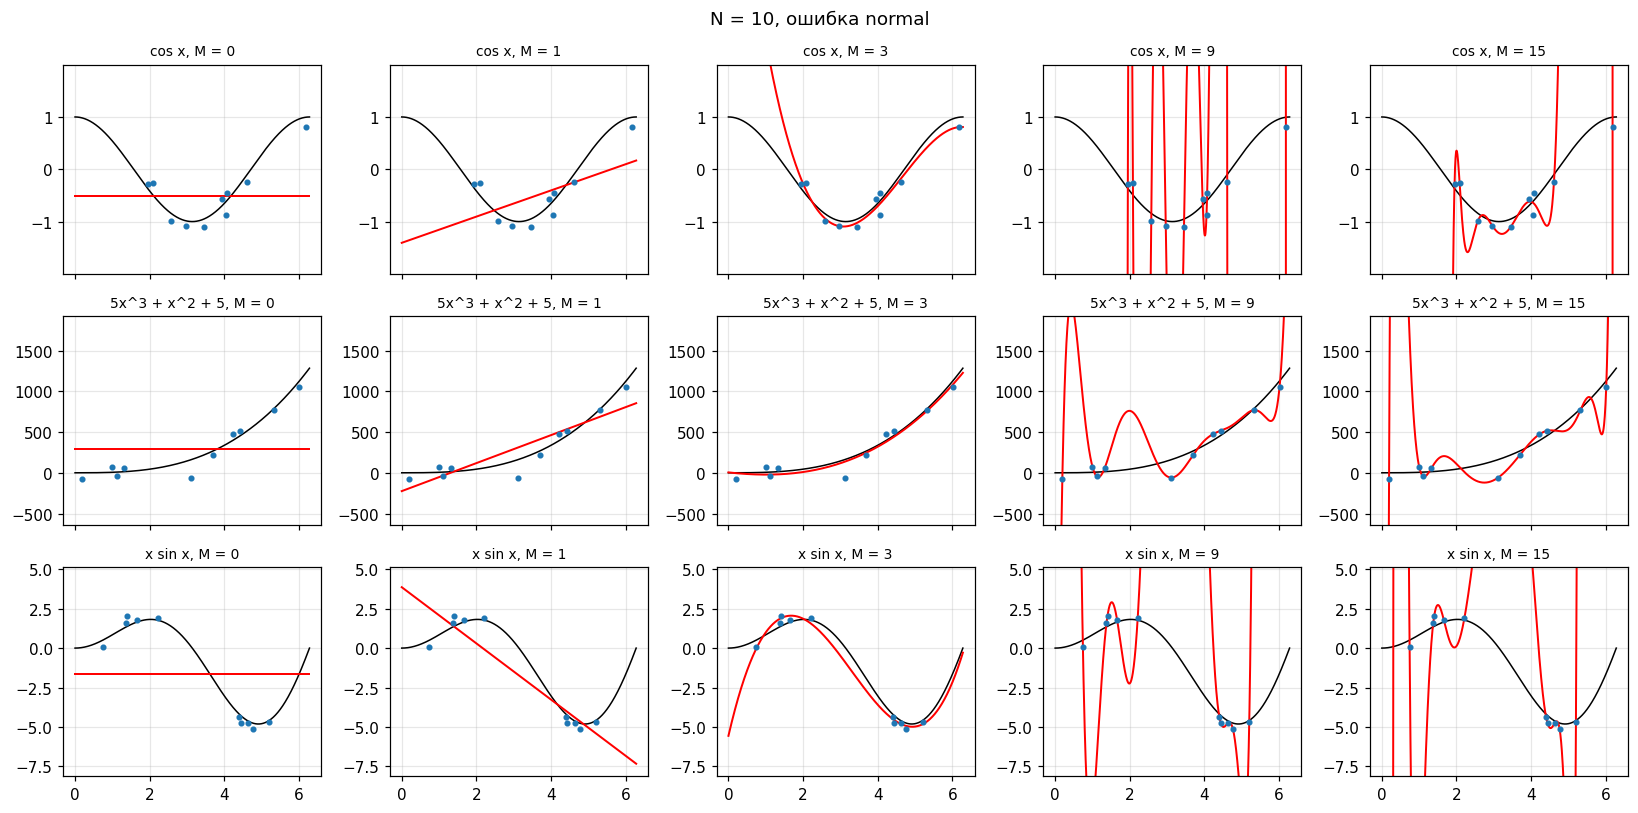

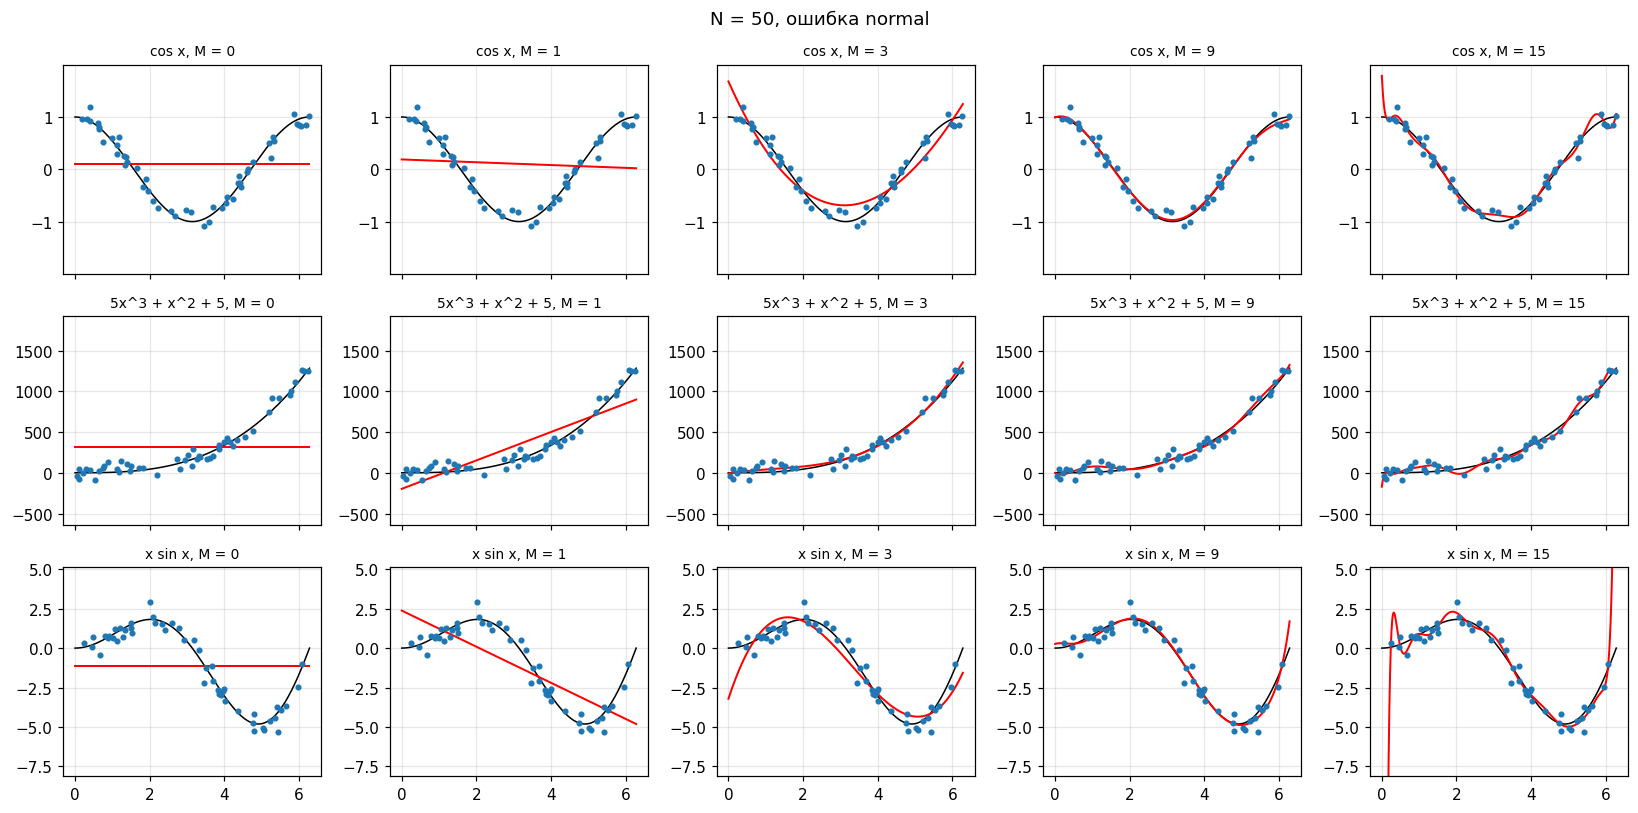

In [4]:
def plot_fits(n, noise="normal", Ms=(0, 1, 3, 9, 15)):
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(3, len(Ms), figsize=(3 * len(Ms), 7.5), sharex=True)
    for row, func in enumerate(FUNCS):
        x, y = make_sample(func, n, noise, rng)
        f = FUNCS[func](GRID)
        pad = 0.5 * (f.max() - f.min())
        for col, M in enumerate(Ms):
            ax = axes[row, col]
            ax.plot(GRID, f, "k", lw=1)
            ax.plot(GRID, predict(fit(x, y, M), GRID), "r", lw=1.3)
            ax.plot(x, y, "o", ms=3)
            ax.set_ylim(f.min() - pad, f.max() + pad)
            ax.set_title(f"{func}, M = {M}", fontsize=9)
    fig.suptitle(f"N = {n}, ошибка {noise}")
    plt.tight_layout()
    plt.show()

plot_fits(10)
plot_fits(50)

### 3.2. Ошибка в зависимости от $M$

Ошибку удобно сравнивать как среднеквадратичное отклонение $E_{RMS} = \sqrt{2E(w)/N}$: оно не
зависит от объёма выборки. Считаем его на обучающей выборке и на **контрольной** выборке из
1000 новых точек, делим на $\sigma$: значение 1 — уровень ошибки измерений.

In [5]:
N_VALUES = [10, 20, 50]
N_REPEATS = 100

rows = []
rng = np.random.default_rng(SEED)
for func in FUNCS:
    for noise_label, noise in NOISES.items():
        for n in N_VALUES:
            for _ in range(N_REPEATS):
                x, y = make_sample(func, n, noise, rng)
                x_test, y_test = make_sample(func, 1000, noise, rng)
                for M in range(16):
                    model = fit(x, y, M)
                    rows.append({"функция": func, "ошибка": noise_label, "N": n, "M": M,
                                 "train": rms(model, x, y, func), "test": rms(model, x_test, y_test, func)})

res3 = (pd.DataFrame(rows)
        .groupby(["функция", "ошибка", "N", "M"])[["train", "test"]].median()
        .reset_index())

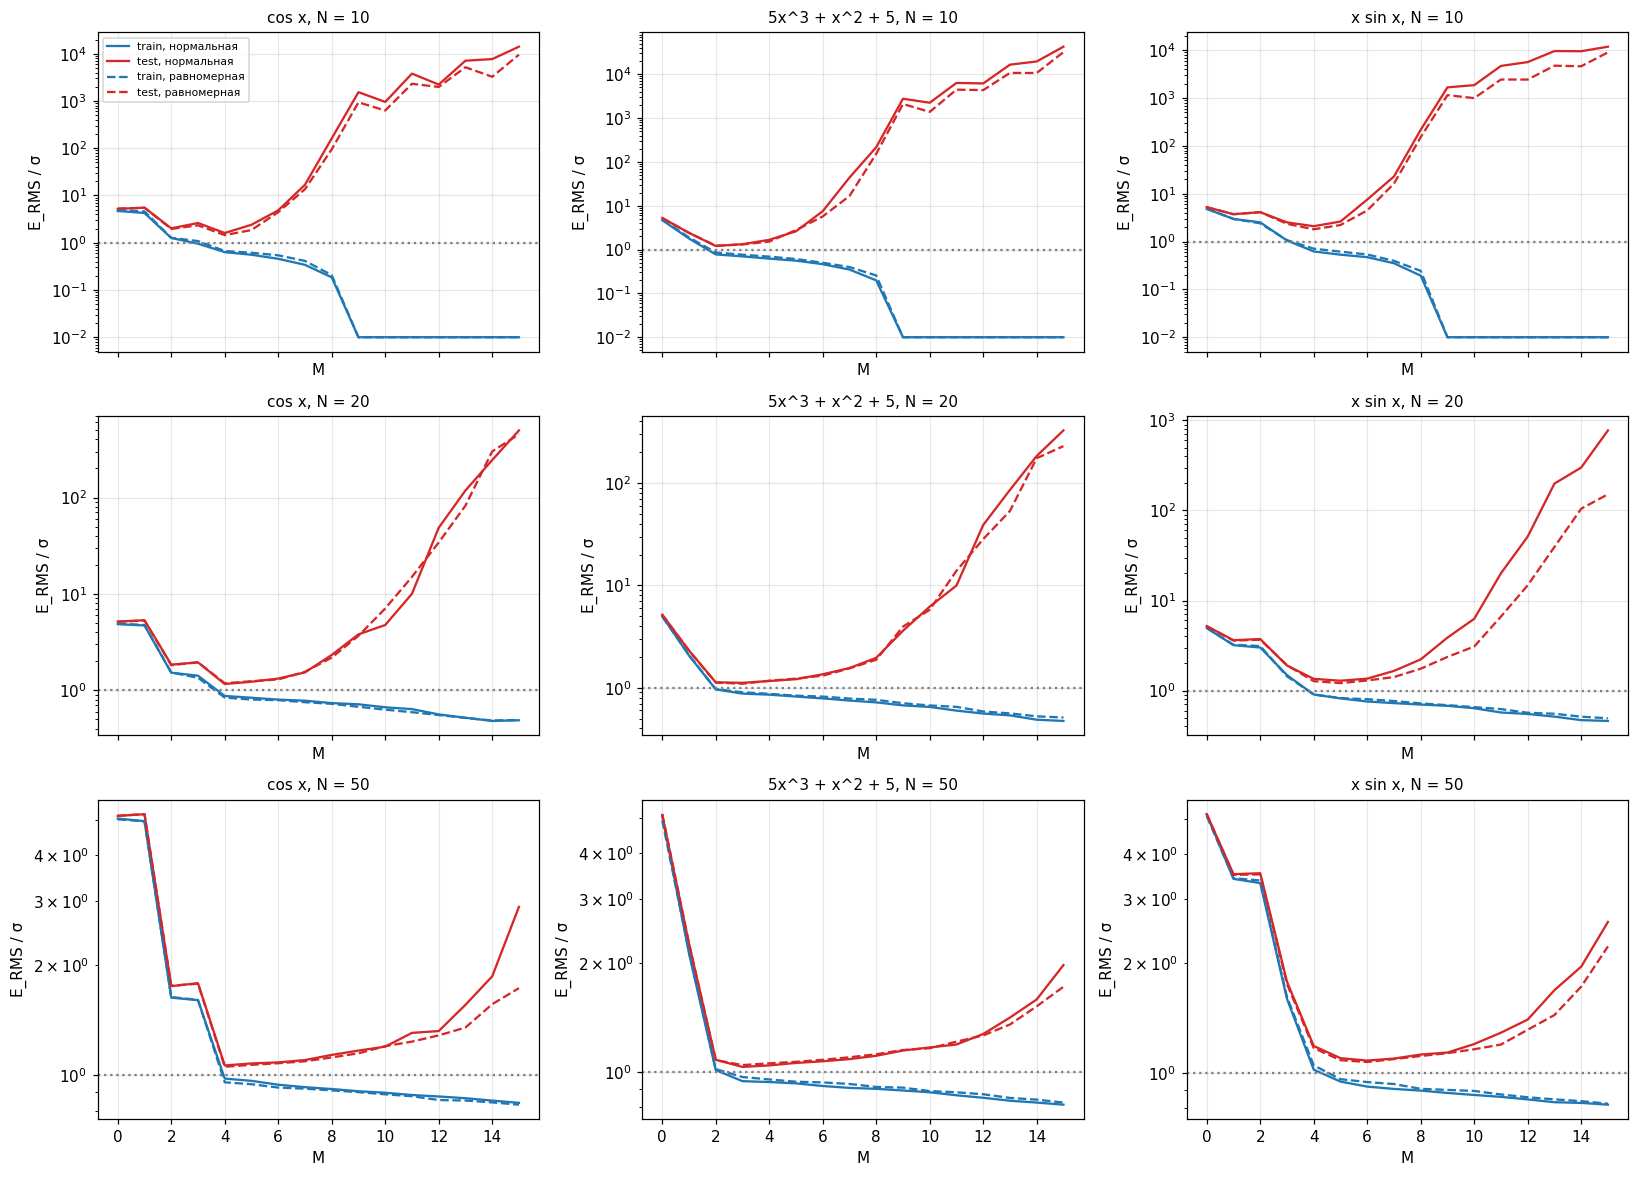

In [6]:
fig, axes = plt.subplots(len(N_VALUES), 3, figsize=(15, 3.6 * len(N_VALUES)), sharex=True)
for i, n in enumerate(N_VALUES):
    for j, func in enumerate(FUNCS):
        ax = axes[i, j]
        for noise_label, style in zip(NOISES, ["-", "--"]):
            s = res3[(res3["функция"] == func) & (res3["ошибка"] == noise_label) & (res3.N == n)]
            ax.semilogy(s.M, s.train.clip(lower=1e-2), "C0" + style, label=f"train, {noise_label}")
            ax.semilogy(s.M, s.test, "C3" + style, label=f"test, {noise_label}")
        ax.axhline(1, color="gray", ls=":")
        ax.set_title(f"{func}, N = {n}", fontsize=10)
        ax.set_xlabel("M"); ax.set_ylabel("E_RMS / σ")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [7]:
# Наилучшее M — минимум ошибки на контрольной выборке
best3 = res3.loc[res3.groupby(["функция", "ошибка", "N"])["test"].idxmin()]
print(best3.pivot_table(index=["функция", "N"], columns="ошибка", values="M").astype(int))
print()
print(best3.pivot_table(index=["функция", "N"], columns="ошибка", values="test").round(2))

ошибка             нормальная  равномерная
функция        N                          
5x^3 + x^2 + 5 10           2            2
               20           3            3
               50           3            3
cos x          10           4            4
               20           4            4
               50           4            4
x sin x        10           4            4
               20           5            5
               50           6            6

ошибка             нормальная  равномерная
функция        N                          
5x^3 + x^2 + 5 10        1.21         1.22
               20        1.12         1.09
               50        1.03         1.05
cos x          10        1.61         1.45
               20        1.16         1.19
               50        1.06         1.05
x sin x        10        2.10         1.81
               20        1.29         1.21
               50        1.08         1.07


In [8]:
# Ошибка на контрольной выборке при нескольких M (нормальная ошибка измерений)
s = res3[res3["ошибка"] == "нормальная"]
print(s[s.M.isin([3, 6, 9, 12, 15])].pivot_table(index=["функция", "M"], columns="N", values="test").round(2))

N                        10      20    50
функция        M                         
5x^3 + x^2 + 5 3       1.33    1.12  1.03
               6       7.51    1.35  1.07
               9    2762.31    3.60  1.15
               12   6169.79   38.90  1.27
               15  42505.80  326.62  1.97
cos x          3       2.62    1.95  1.79
               6       4.85    1.33  1.08
               9    1537.56    3.81  1.17
               12   2230.35   48.58  1.32
               15  14113.22  496.45  2.89
x sin x        3       2.52    1.90  1.78
               6       7.56    1.36  1.08
               9    1676.13    3.87  1.14
               12   5662.31   51.28  1.40
               15  11875.58  774.72  2.60


### 3.3. Выводы по заданию 3

* **Система (7) без нормализации решается неверно.** При $M = 15$ получается $E(w) = 104{,}6$ вместо $18{,}9$ после Z-нормализации; при $M = 3$ и $M = 9$ результаты почти совпадают.
* **Недообучение.** Полином степени $M = 3$ не описывает $\cos x$ и $x \sin x$: ошибка на контрольной выборке $1{,}8\ldots2{,}6\,\sigma$.
* **Переобучение (п. 4.4).** При $N = 10$ ошибка на контрольной выборке равна $1500\ldots2800\,\sigma$ при $M = 9$ и $12\,000\ldots42\,500\,\sigma$ при $M = 15$. С ростом $N$ переобучение исчезает: при $M = 9$ и $N = 50$ ошибка $1{,}1\ldots1{,}2\,\sigma$.
* **Наилучшая степень:** $M = 3$ для $5x^3 + x^2 + 5$ (при $N = 10$ — $M = 2$), $M = 4$ для $\cos x$, $M = 4\ldots6$ для $x \sin x$ (растёт с $N$); ошибка при этом $1{,}03\ldots2{,}10\,\sigma$.
* **Закон распределения ошибки.** При одинаковом $\sigma$ нормальная и равномерная ошибки дают одинаковое наилучшее $M$ во всех 9 случаях и близкие значения ошибки.

## 4. Задание 4. Регуляризация

Минимизируем $E_\lambda(w) = \frac12 \sum_i \bigl(y^{(i)} - \tilde f(w, x^{(i)})\bigr)^2 + \frac\lambda2 \|w\|^2$ (8),
где $\|w\|^2 = \sum_{i=1}^M w_i^2$ — без $w_0$ (п. 4.5, стр. 79). Дифференцирование даёт систему (7) с
добавкой на диагонали: $\sum_j a_{ij} w_j + \lambda w_i = b_i$ при $i \ge 1$, уравнение для $i = 0$ не меняется.

При $\lambda > 0$ `fit` нормирует $x$ **минимаксно** (12) в $[0, 1]$: все степени $x^i$ тогда не больше 1, и штраф
$\lambda w_i^2$ одинаково ограничивает вклад всех слагаемых полинома. С Z-нормализацией (13) $|x|$ доходит до 1,7,
$x^{15}$ — до $3 \cdot 10^3$, и штраф почти не сдерживает старшие слагаемые. При $\lambda = 0$ остаётся Z-нормализация:
минимаксная нормализация даёт для системы (7) заметно худшую точность решения.

### 4.1. Ошибка в зависимости от $\lambda$

Для каждой пары $(M, \lambda)$ — медиана $E_{RMS}/\sigma$ по 100 выборкам, контрольная выборка — 1000 новых точек.
Переобучение в задании 3 возникало при $N \le 20$, поэтому берём $N = 10$ и $N = 20$.

In [9]:
N_VALUES_REG = [10, 20]
LAMS = np.r_[0, np.logspace(-8, 2, 21)]

rows = []
rng = np.random.default_rng(SEED)
for func in FUNCS:
    for noise_label, noise in NOISES.items():
        for n in N_VALUES_REG:
            for _ in range(N_REPEATS):
                x, y = make_sample(func, n, noise, rng)
                x_test, y_test = make_sample(func, 1000, noise, rng)
                for M in range(16):
                    for lam in LAMS:
                        model = fit(x, y, M, lam)
                        rows.append({"функция": func, "ошибка": noise_label, "N": n, "M": M, "λ": lam,
                                     "train": rms(model, x, y, func), "test": rms(model, x_test, y_test, func)})

res4 = (pd.DataFrame(rows)
        .groupby(["функция", "ошибка", "N", "M", "λ"])[["train", "test"]].median()
        .reset_index())

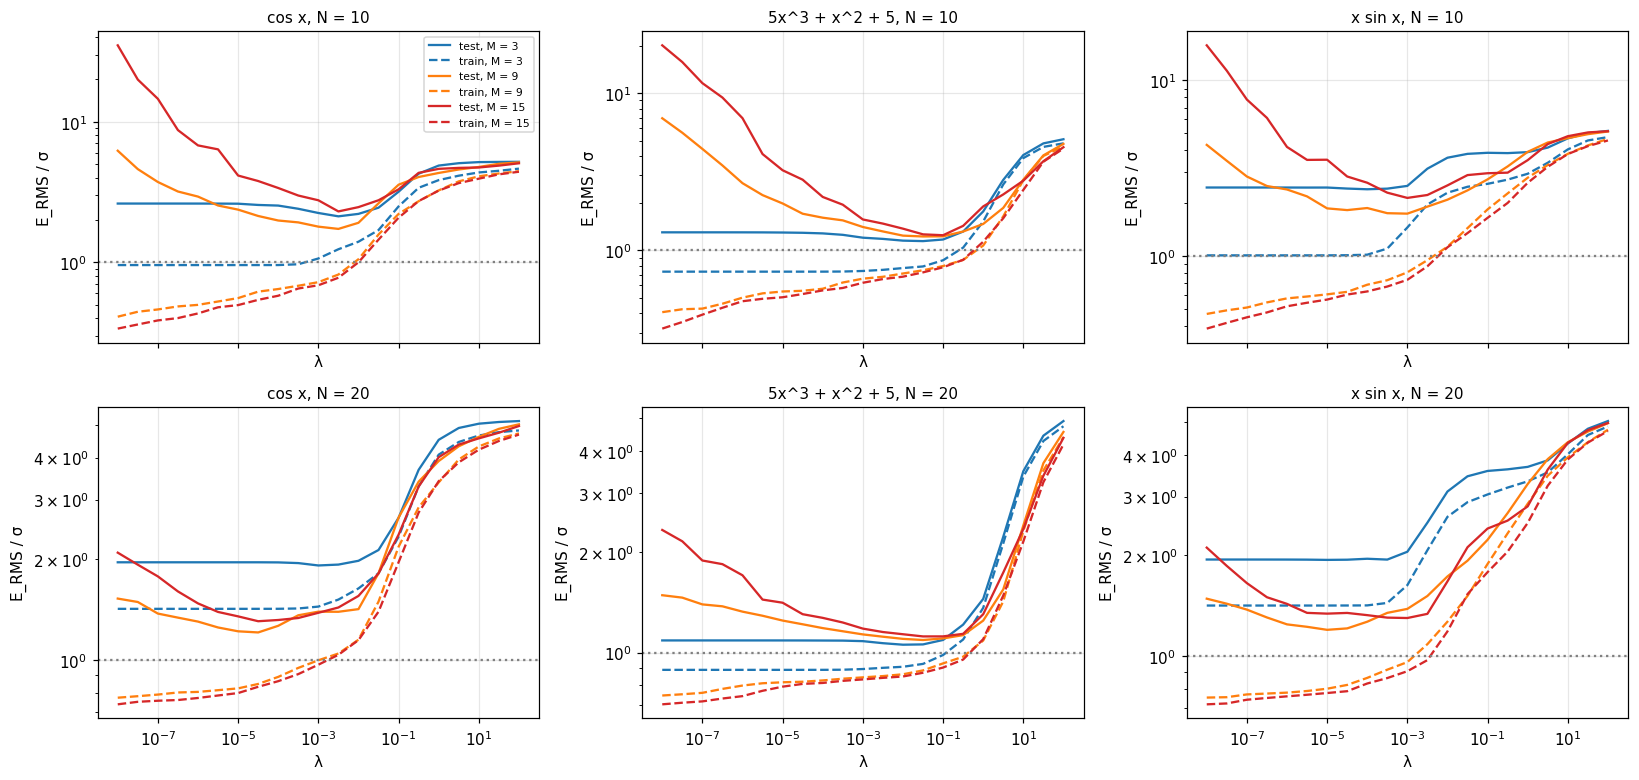

In [10]:
# Сплошные линии — контрольная выборка, пунктир — обучающая; нормальная ошибка измерений
fig, axes = plt.subplots(len(N_VALUES_REG), 3, figsize=(15, 3.6 * len(N_VALUES_REG)), sharex=True)
for i, n in enumerate(N_VALUES_REG):
    for j, func in enumerate(FUNCS):
        ax = axes[i, j]
        for M, color in zip([3, 9, 15], ["C0", "C1", "C3"]):
            s = res4[(res4["функция"] == func) & (res4["ошибка"] == "нормальная") & (res4.N == n) & (res4.M == M) & (res4["λ"] > 0)]
            ax.loglog(s["λ"], s.test, color, label=f"test, M = {M}")
            ax.loglog(s["λ"], s.train, color + "--", label=f"train, M = {M}")
        ax.axhline(1, color="gray", ls=":")
        ax.set_title(f"{func}, N = {n}", fontsize=10)
        ax.set_xlabel("λ"); ax.set_ylabel("E_RMS / σ")
axes[0, 0].legend(fontsize=7)
plt.tight_layout()
plt.show()

### 4.2. Значения $M$ и $\lambda$, устраняющие переобучение

Для $M = 9$ и $M = 15$ сравниваем ошибку на контрольной выборке без регуляризации и при наилучшем $\lambda$.

In [11]:
def best_lam(s):
    b = s.loc[s.test.idxmin()]
    return pd.Series({"test, λ = 0": s.loc[s["λ"] == 0, "test"].iloc[0], "λ*": b["λ"], "test, λ*": b.test})

pd.set_option("display.float_format", lambda v: f"{v:.3g}")
tab = (res4[res4.M.isin([9, 15])]
       .groupby(["функция", "N", "M", "ошибка"])[["λ", "test"]].apply(best_lam)
       .unstack("ошибка").swaplevel(axis=1)
       .reindex(columns=pd.MultiIndex.from_product([NOISES, ["test, λ = 0", "λ*", "test, λ*"]])))
print(tab.to_string())

                      нормальная                   равномерная                  
                     test, λ = 0       λ* test, λ* test, λ = 0       λ* test, λ*
функция        N  M                                                             
5x^3 + x^2 + 5 10 9     1.49e+03   0.0316     1.23    1.44e+03   0.0316     1.24
                  15    6.99e+03      0.1     1.25       1e+04   0.0316      1.3
               20 9         5.27   0.0316     1.09         3.2     0.01     1.11
                  15         847   0.0316     1.12         226   0.0316     1.13
cos x          10 9     1.54e+03  0.00316     1.73    1.77e+03  0.00316     1.66
                  15    1.41e+04  0.00316      2.3    2.33e+04    0.001     2.65
               20 9         3.81 3.16e-05     1.21        4.83 3.16e-05     1.23
                  15         496 3.16e-05      1.3         482 0.000316     1.33
x sin x        10 9          772    0.001     1.74    1.06e+03   0.0001     1.66
                  15    9.05

In [12]:
# Наилучшая пара (M, λ) на контрольной выборке и наилучшее M без регуляризации (λ = 0)
key = ["функция", "ошибка", "N"]
best4 = res4.loc[res4.groupby(key).test.idxmin(), key + ["M", "λ", "test"]].set_index(key)
best4_0 = res4[res4["λ"] == 0].pipe(lambda s: s.loc[s.groupby(key).test.idxmin(), key + ["M", "test"]]).set_index(key)
print(best4.join(best4_0, rsuffix=", λ = 0").to_string())

                               M        λ  test  M, λ = 0  test, λ = 0
функция        ошибка      N                                          
5x^3 + x^2 + 5 нормальная  10  4      0.1  1.13         2         1.23
                           20  3     0.01  1.06         3         1.09
               равномерная 10  3   0.0316  1.14         2         1.24
                           20  3   0.0316  1.06         3         1.12
cos x          нормальная  10  4    1e-06   1.6         4         1.61
                           20  4 3.16e-06  1.16         4         1.16
               равномерная 10  4    1e-05  1.46         4         1.51
                           20  4 3.16e-06  1.17         4         1.17
x sin x        нормальная  10  5 0.000316  1.51         4         1.68
                           20  7 3.16e-06  1.19         5         1.28
               равномерная 10  5    0.001  1.54         4         1.97
                           20  6    1e-06  1.22         5         1.24


### 4.3. Восстановленные зависимости

Как на рис. 4.3: чёрная линия — $f(x)$, красная — минимизация (2) ($\lambda = 0$), зелёная — минимизация (8)
при найденном $\lambda^*$, точки — выборка.

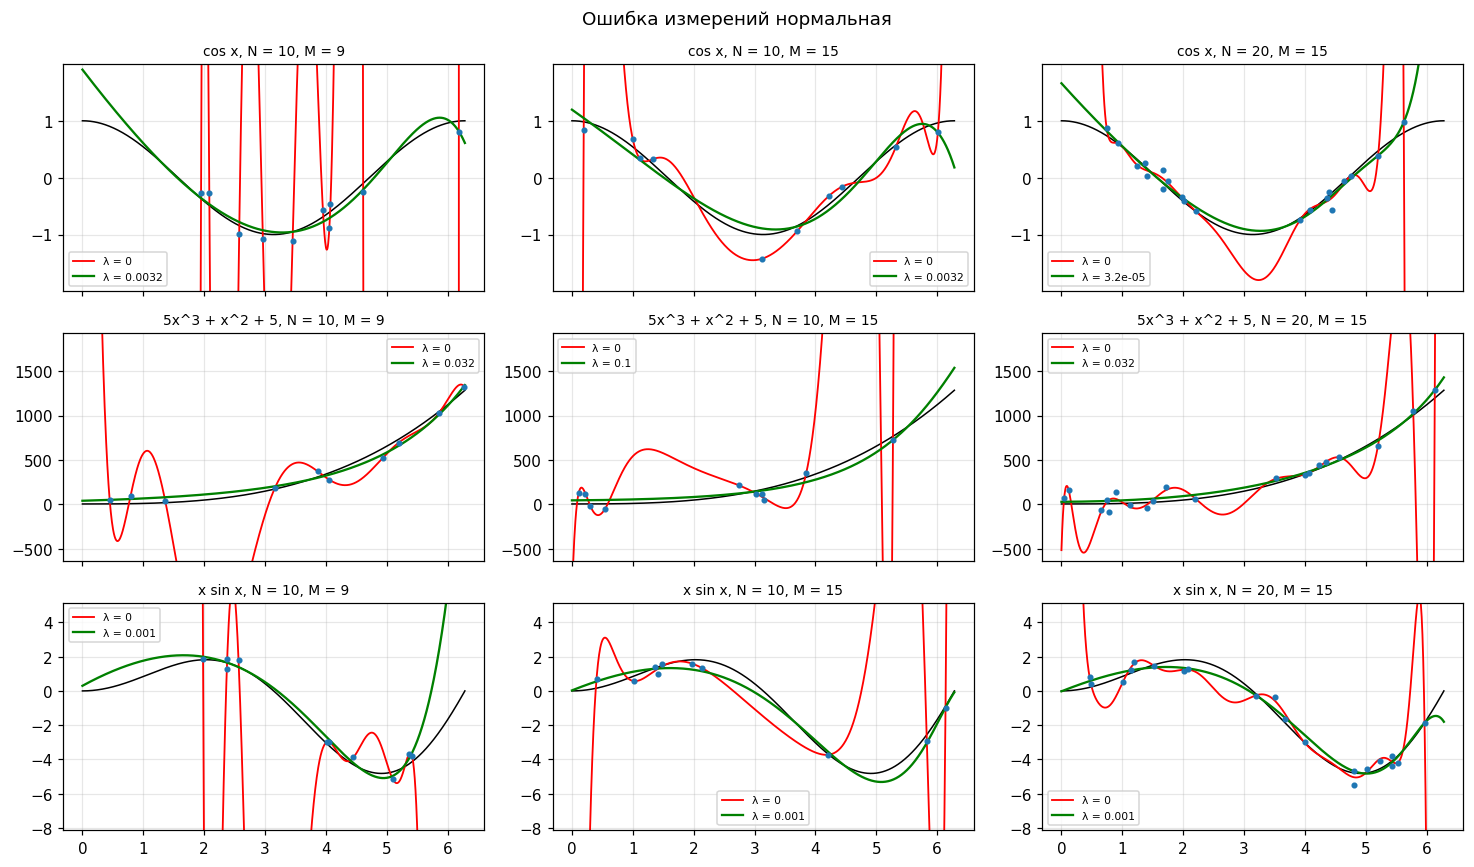

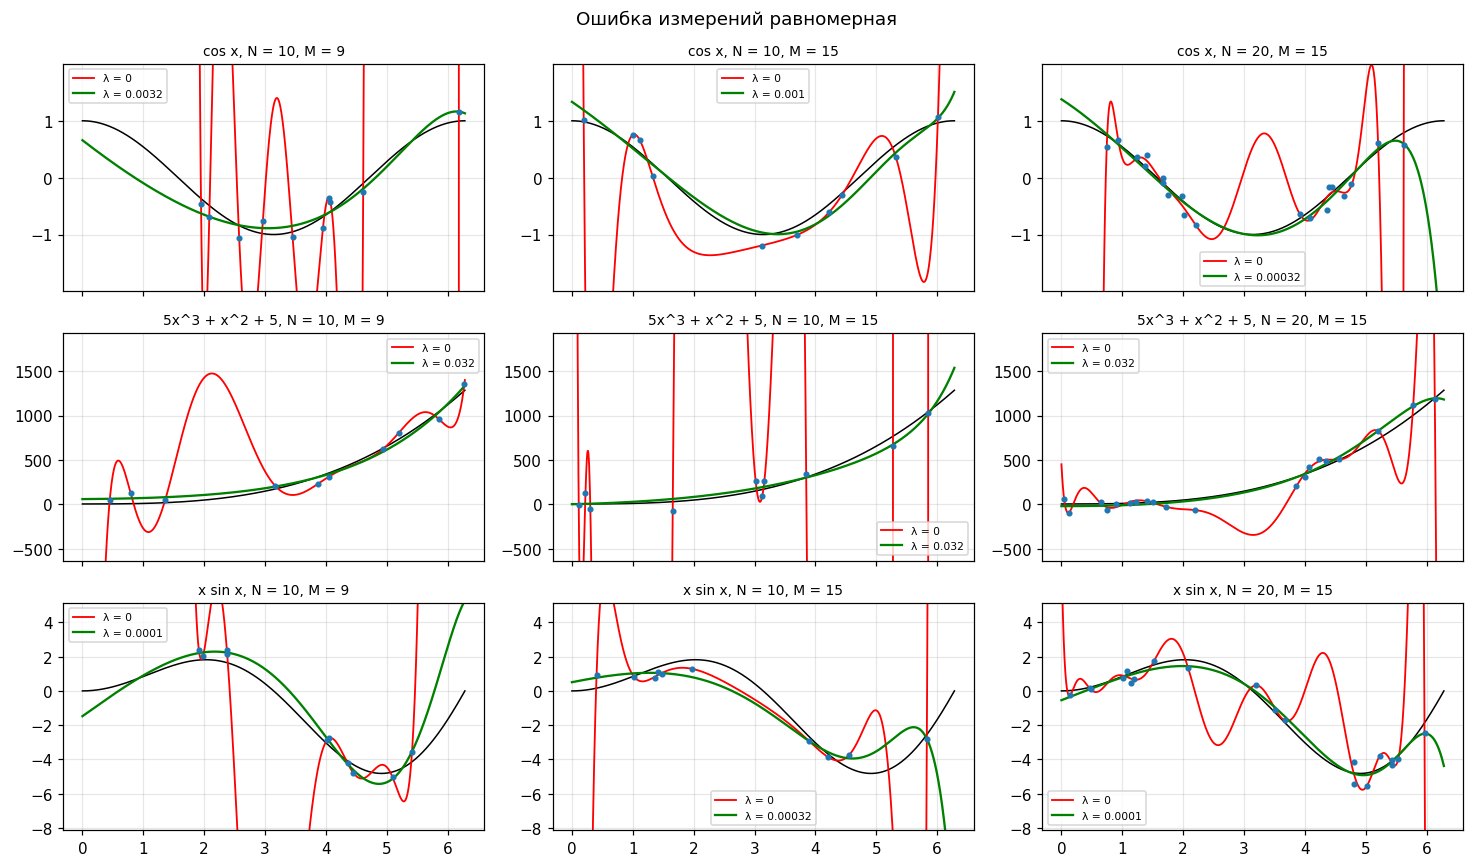

In [13]:
def plot_reg(noise_label, cases=((10, 9), (10, 15), (20, 15))):
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(3, len(cases), figsize=(4.5 * len(cases), 8), sharex=True)
    for row, func in enumerate(FUNCS):
        f = FUNCS[func](GRID)
        pad = 0.5 * (f.max() - f.min())
        for col, (n, M) in enumerate(cases):
            x, y = make_sample(func, n, NOISES[noise_label], rng)
            lam = tab.loc[(func, n, M), (noise_label, "λ*")]
            ax = axes[row, col]
            ax.plot(GRID, f, "k", lw=1)
            ax.plot(GRID, predict(fit(x, y, M), GRID), "r", lw=1.2, label="λ = 0")
            ax.plot(GRID, predict(fit(x, y, M, lam), GRID), "g", lw=1.5, label=f"λ = {lam:.2g}")
            ax.plot(x, y, "o", ms=3)
            ax.set_ylim(f.min() - pad, f.max() + pad)
            ax.set_title(f"{func}, N = {n}, M = {M}", fontsize=9)
            ax.legend(fontsize=7)
    fig.suptitle(f"Ошибка измерений {noise_label}")
    plt.tight_layout()
    plt.show()

plot_reg("нормальная")
plot_reg("равномерная")

In [14]:
# Чем больше λ, тем меньше ||w|| (п. 4.5): одна выборка cos x, N = 10, M = 15
x, y = make_sample("cos x", 10, "normal", np.random.default_rng(SEED))
for lam in [0, 1e-6, 1e-3, 1, 100]:
    model = fit(x, y, 15, lam)
    print(f"λ = {lam:<6g} ||w|| = {np.sqrt(np.sum(model[0][1:] ** 2)):10.3g}   E_RMS/σ (train) = {rms(model, x, y, 'cos x'):.2f}")

λ = 0      ||w|| =       8.36   E_RMS/σ (train) = 0.69
λ = 1e-06  ||w|| =       40.3   E_RMS/σ (train) = 0.82
λ = 0.001  ||w|| =       8.78   E_RMS/σ (train) = 1.01
λ = 1      ||w|| =      0.384   E_RMS/σ (train) = 2.22
λ = 100    ||w|| =     0.0443   E_RMS/σ (train) = 3.58


### 4.4. Выводы по заданию 4

* **Регуляризация устраняет переобучение.** При $N = 10$ и $M = 9$ ошибка на контрольной выборке падает с $770\ldots1770\,\sigma$ до $1{,}2\ldots1{,}7\,\sigma$, при $M = 15$ — с $9000\ldots23\,000\,\sigma$ до $1{,}25\ldots2{,}65\,\sigma$. При $N = 20$ и $M = 15$ — с $220\ldots850\,\sigma$ до $1{,}1\ldots1{,}3\,\sigma$.
* **Найденные $\lambda^*$:** $10^{-2}\ldots10^{-1}$ для $5x^3 + x^2 + 5$, $3\cdot10^{-5}\ldots3\cdot10^{-3}$ для $\cos x$ и $10^{-5}\ldots10^{-3}$ для $x \sin x$. Кубическому полиному старшие степени не нужны, поэтому допустим более сильный штраф.
* **Предел регуляризации.** Для $\cos x$ и $x \sin x$ при $N = 10$, $M = 15$ ошибка $2{,}0\ldots2{,}65\,\sigma$ остаётся выше, чем у лучшего полинома без регуляризации ($M = 4$, $1{,}5\ldots2{,}0\,\sigma$).
* **Слишком большое $\lambda$ даёт недообучение.** Для $\cos x$ ($N = 10$, $M = 15$) ошибка на обучающей выборке растёт с $0{,}82\,\sigma$ при $\lambda = 10^{-6}$ до $2{,}2\,\sigma$ при $\lambda = 1$ и $3{,}6\,\sigma$ при $\lambda = 100$, $\|w\|$ падает с 40 до 0,04. Строка $\lambda = 0$ считается с другой нормализацией, поэтому её $\|w\|$ не сопоставим.
* **Наилучшие пары $(M, \lambda)$:** $M = 3\ldots4$, $\lambda = 0{,}01\ldots0{,}1$ для $5x^3 + x^2 + 5$; $M = 4$, $\lambda = 10^{-6}\ldots10^{-5}$ для $\cos x$ (ошибка как без регуляризации); $M = 5\ldots7$, $\lambda = 10^{-6}\ldots10^{-3}$ для $x \sin x$. Для $x \sin x$ регуляризация позволяет взять $M$ выше, чем без неё ($4\ldots5$), и снижает ошибку, например при $N = 10$ с $1{,}7\ldots2{,}0\,\sigma$ до $1{,}5\,\sigma$.
* **Закон распределения ошибки.** Нормальная и равномерная ошибки дают $\lambda^*$, отличающиеся не более чем на порядок, и близкие значения ошибки.

## 5. Задание 5. Кросс-валидация

Выборка случайно делится на $K$ равных частей (п. 4.6, стр. 82). Каждая часть по очереди становится контрольной, на остальных для каждой пары $(M, \lambda)$ минимизируется (8). Пары сравниваются по ошибке $E(w)$ (2) на контрольных частях, усреднённой по всем $K$ запускам; берётся пара с наименьшей ошибкой.

Выборки малы ($N = 10$ и $N = 20$), поэтому $K = N$ — поэлементная кросс-валидация, как рекомендует пособие. Сетка пар та же, что в задании 4: $M \in \{0, \ldots, 15\}$, 22 значения $\lambda$.

In [15]:
MS = list(range(16))

def cv_errors(x, y, K, rng):
    # Матрица [M, λ] ошибок кросс-валидации sqrt(E/N) (в единицах y): K частей, одинаковое разбиение для всех пар
    sq = np.zeros((len(MS), len(LAMS)))
    for test in np.array_split(rng.permutation(len(x)), K):
        train = np.ones(len(x), bool)
        train[test] = False
        for i, M in enumerate(MS):
            for j, lam in enumerate(LAMS):
                sq[i, j] += np.sum((y[test] - predict(fit(x[train], y[train], M, lam), x[test])) ** 2)
    return np.sqrt(sq / len(x))

def best_pair(err):
    i, j = np.unravel_index(np.argmin(err), err.shape)
    return MS[i], LAMS[j]

### 5.1. Выбор пары на одной выборке

Нормальная ошибка измерений, $N = 20$. Сверху — ошибка кросс-валидации $\log_{10}(E_{RMS}^{CV}/\sigma)$ для всех пар, звёздочка — наилучшая. Снизу — чёрная линия $f(x)$, красная — лучшая степень без регуляризации ($\lambda = 0$) по той же кросс-валидации, зелёная — лучшая пара $(M, \lambda)$.

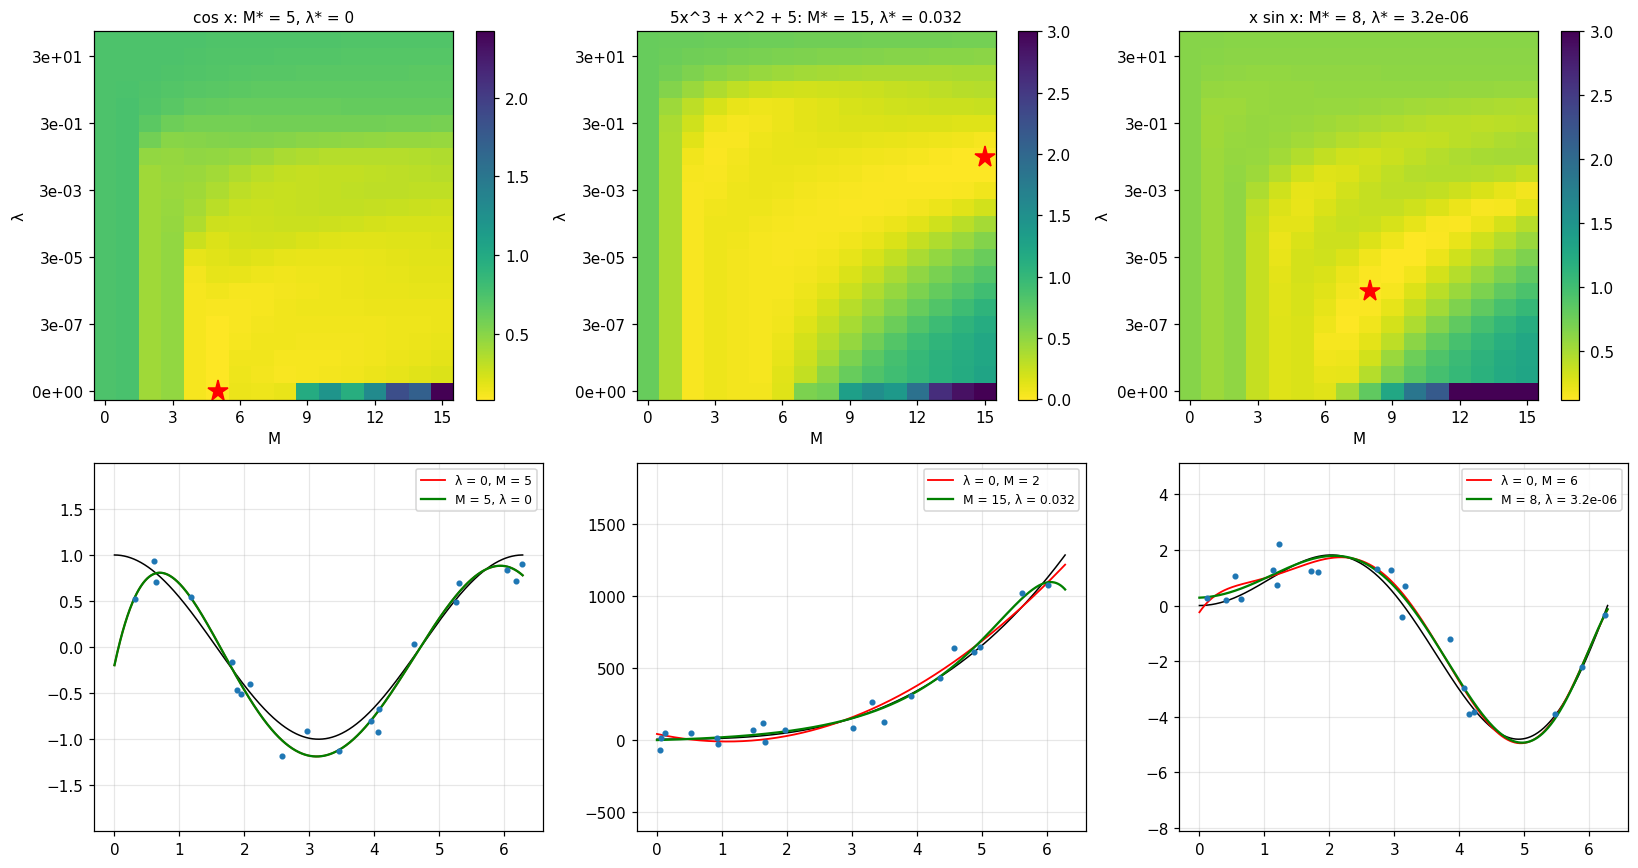

In [16]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for col, func in enumerate(FUNCS):
    x, y = make_sample(func, 20, "normal", rng)
    err = cv_errors(x, y, len(x), rng)
    M_best, lam_best = best_pair(err)
    M0 = MS[np.argmin(err[:, 0])]

    ax = axes[0, col]
    im = ax.imshow(np.log10(np.minimum(err.T / SIGMA[func], 1e3)), origin="lower", aspect="auto", cmap="viridis_r")
    ax.plot(M_best, list(LAMS).index(lam_best), "r*", ms=14)
    ax.set_xticks(MS[::3], MS[::3])
    ax.set_yticks(range(0, len(LAMS), 4), [f"{l:.0e}" for l in LAMS[::4]])
    ax.set_xlabel("M"); ax.set_ylabel("λ"); ax.grid(False)
    ax.set_title(f"{func}: M* = {M_best}, λ* = {lam_best:.2g}", fontsize=10)
    fig.colorbar(im, ax=ax)

    ax = axes[1, col]
    f = FUNCS[func](GRID)
    pad = 0.5 * (f.max() - f.min())
    ax.plot(GRID, f, "k", lw=1)
    ax.plot(GRID, predict(fit(x, y, M0), GRID), "r", lw=1.2, label=f"λ = 0, M = {M0}")
    ax.plot(GRID, predict(fit(x, y, M_best, lam_best), GRID), "g", lw=1.5, label=f"M = {M_best}, λ = {lam_best:.2g}")
    ax.plot(x, y, "o", ms=3)
    ax.set_ylim(f.min() - pad, f.max() + pad)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 5.2. Качество выбора по 100 выборкам

Для каждой выборки из задания 4 кросс-валидацией выбираем пару $(M^*, \lambda^*)$ и считаем её ошибку на контрольной выборке из 1000 новых точек. Для сравнения: лучшая пара по самой контрольной выборке (нижняя граница) и лучшее $M$ без регуляризации ($\lambda = 0$), выбранное той же кросс-валидацией.

In [17]:
def test_errors(x, y, x_test, y_test, func):
    # Ошибка на контрольной выборке для всех пар (M, λ), в единицах σ
    return np.array([[rms(fit(x, y, M, lam), x_test, y_test, func) for lam in LAMS] for M in MS])

rows = []
rng = np.random.default_rng(SEED)
for func in FUNCS:
    for noise_label, noise in NOISES.items():
        for n in N_VALUES_REG:
            for _ in range(N_REPEATS):
                x, y = make_sample(func, n, noise, rng)
                x_test, y_test = make_sample(func, 1000, noise, rng)
                err = cv_errors(x, y, n, rng)
                te = test_errors(x, y, x_test, y_test, func)
                M_cv, lam_cv = best_pair(err)
                M0 = MS[np.argmin(err[:, 0])]
                rows.append({"функция": func, "ошибка": noise_label, "N": n,
                             "M*": M_cv, "λ*": lam_cv,
                             "test, CV": te[M_cv, list(LAMS).index(lam_cv)],
                             "test, лучшая": te.min(),
                             "test, λ = 0": te[M0, 0]})

cv_res = pd.DataFrame(rows)
cv_tab = (cv_res.groupby(["функция", "N", "ошибка"])
          [["M*", "λ*", "test, CV", "test, лучшая", "test, λ = 0"]].median())
print(cv_tab.to_string())

                               M*       λ*  test, CV  test, лучшая  test, λ = 0
функция        N  ошибка                                                       
5x^3 + x^2 + 5 10 нормальная    5   0.0316      1.33          1.07         1.31
                  равномерная   5   0.0316      1.32          1.07         1.24
               20 нормальная    5   0.0316      1.13          1.05         1.15
                  равномерная   5   0.0316      1.16          1.05         1.17
cos x          10 нормальная    6   0.0001      1.97          1.23            2
                  равномерная   5   0.0001       2.3          1.23         2.11
               20 нормальная    6    1e-05      1.26           1.1         1.19
                  равномерная   6    1e-05      1.31          1.12         1.26
x sin x        10 нормальная    5   0.0001      2.45          1.26         2.94
                  равномерная   5 0.000208      2.16          1.24         3.12
               20 нормальная    7    1e-

In [18]:
# Как часто выбираются разные M* и какие λ* (доли по 100 выборкам)
print(cv_res.groupby(["функция", "N"])["M*"].agg(lambda s: dict(s.value_counts().head(3))).to_string())
print()
print((cv_res.assign(**{"λ*": cv_res["λ*"].map(lambda v: 0 if v == 0 else int(round(np.log10(v))))})
       .groupby(["функция", "N"])["λ*"].agg(lambda s: dict(s.value_counts().head(3))).to_string()))

функция         N 
5x^3 + x^2 + 5  10    {4: 35, 2: 30, 5: 29}
                20    {3: 38, 5: 26, 4: 25}
cos x           10    {4: 32, 5: 26, 7: 22}
                20    {4: 53, 5: 35, 6: 26}
x sin x         10    {4: 50, 5: 33, 3: 24}
                20    {4: 37, 5: 36, 7: 23}

функция         N 
5x^3 + x^2 + 5  10     {0: 65, -2: 48, -1: 33}
                20     {-2: 64, 0: 47, -1: 34}
cos x           10    {-4: 58, -2: 47, -6: 27}
                20    {-4: 56, -6: 40, -5: 35}
x sin x         10    {-4: 71, -3: 30, -5: 22}
                20    {-4: 53, -6: 51, -3: 26}


### 5.3. Выводы по заданию 5

* **Кросс-валидация выбирает пару по одной выборке**, без контрольной, но хуже лучшей возможной пары: при $N = 20$ ошибка $1{,}13\ldots1{,}39\,\sigma$ против $1{,}05\ldots1{,}16\,\sigma$, при $N = 10$ — $1{,}3\ldots2{,}5\,\sigma$ против $1{,}07\ldots1{,}26\,\sigma$.
* **Выбор неустойчив.** По 200 выборкам $M^*$ принимает 3 и более значений (например, для $\cos x$, $N = 20$: 4, 5, 6), а $\lambda^*$ — разбросан на несколько порядков: хорошая ошибка достигается на широкой области пар (задание 4).
* **Наилучшая пара** (медианы): $M^* = 5$, $\lambda^* \approx 3\cdot10^{-2}$ для $5x^3 + x^2 + 5$; $M^* = 5\ldots6$, $\lambda^* = 10^{-5}\ldots10^{-4}$ для $\cos x$; $M^* = 5\ldots7$, $\lambda^* = 10^{-5}\ldots10^{-4}$ для $x \sin x$. Порядок $\lambda^*$ согласуется с заданием 4.
* **Выигрыш от регуляризации** заметен только для $x \sin x$ при $N = 10$: ошибка $2{,}2\ldots2{,}5\,\sigma$ вместо $2{,}9\ldots3{,}1\,\sigma$ при выборе одного $M$. Для остальных функций ошибки практически равны (например, $\cos x$, $N = 10$, нормальная ошибка: $2{,}0\,\sigma$ в обоих случаях).
* **Поэлементная кросс-валидация** ($K = N$) требует $N$ обучений на каждую из 352 пар $(M, \lambda)$.